In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")


## Data Preparation

In [3]:
df = pd.read_csv("C:/Users/bhanu/Documents/AI_Engineering/Python/Projects\Logistic_Regression_Using_Scikit_Learn/data/framingham.csv")
df.head()


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [4]:
df.shape


(4238, 16)

In [5]:
df.duplicated().sum()


np.int64(0)

In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [7]:
df.describe()


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4238.000000,4238.000000,4133.000000,4238.000000,4209.000000,4185.000000,4238.000000,4238.000000,4238.000000,4188.000000,4238.000000,4238.000000,4219.000000,4237.000000,3850.000000,4238.000000
mean,0.429212,49.584946,1.978950,0.494101,9.003089,0.029630,0.005899,0.310524,0.025720,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753,0.151958
std,0.495022,8.572160,1.019791,0.500024,11.920094,0.169584,0.076587,0.462763,0.158316,44.590334,22.038097,11.910850,4.080111,12.026596,23.959998,0.359023
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,89.875000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


## Handling Missing Values

In [8]:
df.isna().sum()


male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [9]:
df["cigsPerDay"] = df.groupby("male")["cigsPerDay"].transform(
    lambda x: x.fillna(x.mean())
)


In [10]:
df["cigsPerDay"] = np.ceil(df["cigsPerDay"])


In [11]:
df["BPMeds"].fillna(df["BPMeds"].mode()[0], inplace=True)


0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
4233    0.0
4234    0.0
4235    0.0
4236    0.0
4237    0.0
Name: BPMeds, Length: 4238, dtype: float64

In [12]:
df["totChol"].fillna(df["totChol"].mean(), inplace=True)


0       195.0
1       250.0
2       245.0
3       225.0
4       285.0
        ...  
4233    313.0
4234    207.0
4235    248.0
4236    210.0
4237    269.0
Name: totChol, Length: 4238, dtype: float64

In [13]:
df["BMI"].fillna(df["BMI"].mean(), inplace=True)


0       26.97
1       28.73
2       25.34
3       28.58
4       23.10
        ...  
4233    25.97
4234    19.71
4235    22.00
4236    19.16
4237    21.47
Name: BMI, Length: 4238, dtype: float64

In [14]:
df["glucose"].fillna(df["glucose"].mean(), inplace=True)


0        77.000000
1        76.000000
2        70.000000
3       103.000000
4        85.000000
           ...    
4233     86.000000
4234     68.000000
4235     86.000000
4236     81.966753
4237    107.000000
Name: glucose, Length: 4238, dtype: float64

In [15]:
df["heartRate"].fillna(df["heartRate"].mean(), inplace=True)


0       80.0
1       95.0
2       75.0
3       65.0
4       85.0
        ... 
4233    66.0
4234    65.0
4235    84.0
4236    86.0
4237    80.0
Name: heartRate, Length: 4238, dtype: float64

In [16]:
df.drop(columns=["education"], inplace=True)


In [17]:
df.isna().sum()


male                 0
age                  0
currentSmoker        0
cigsPerDay           0
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

## Exploratory Data Analysis (EDA)

In [18]:
df.head(1)
    

,male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0


In [19]:
sns.set_style("darkgrid")
sns.set_palette("rainbow")


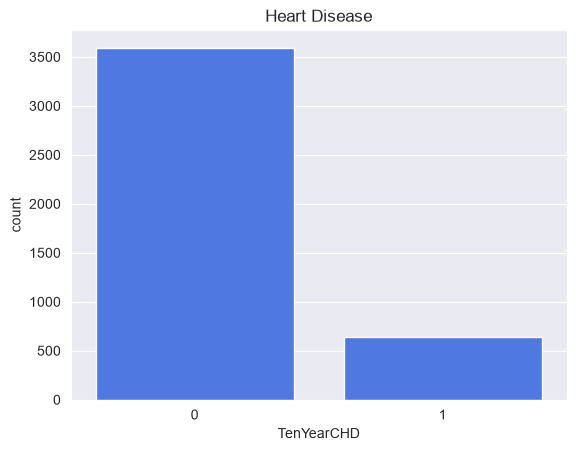

In [20]:
sns.countplot(data=df, x="TenYearCHD")
plt.title("Heart Disease")
plt.show()


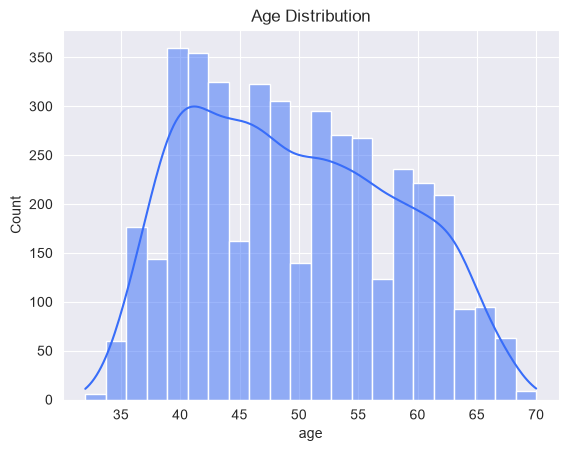

In [21]:
sns.histplot(df["age"], kde=True)
plt.title("Age Distribution")
plt.show()


In [22]:
piv = df.pivot_table(index = 'male' , values = 'TenYearCHD' ,aggfunc='sum')
piv.reset_index(inplace=True)
piv


,male,TenYearCHD
0,0,301
1,1,343


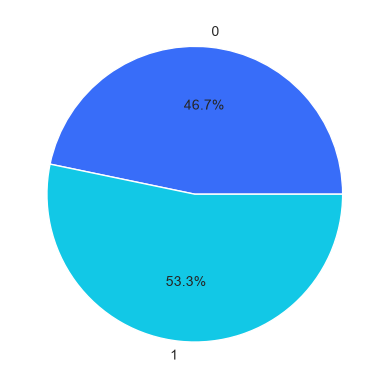

In [23]:
plt.pie(piv['TenYearCHD'],labels=piv['male'],autopct='%1.1f%%')


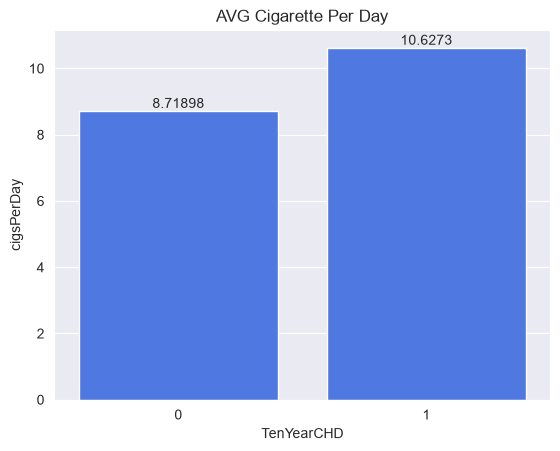

In [24]:
ax = sns.barplot(x="TenYearCHD", y="cigsPerDay", data=df, ci=None)
plt.title("AVG Cigarette Per Day")
for i in ax.containers:
    ax.bar_label(i)
plt.show()


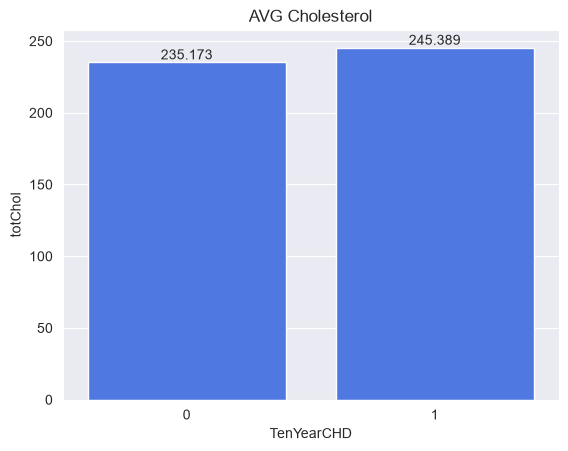

In [25]:
ax = sns.barplot(x="TenYearCHD", y="totChol", data=df, ci=None)
plt.title("AVG Cholesterol")
for i in ax.containers:
    ax.bar_label(i)
plt.show()


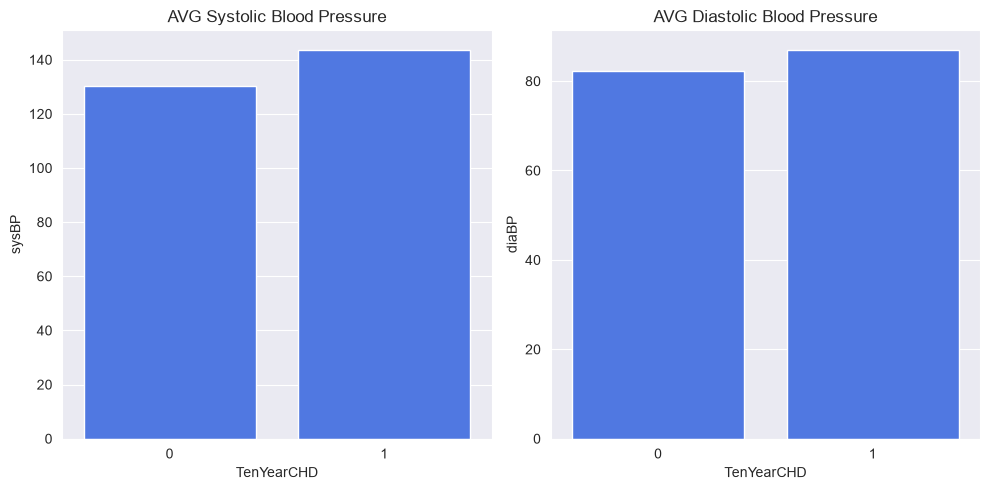

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

sns.barplot(x="TenYearCHD", y="sysBP", data=df, ci=None, ax=ax[0])
ax[0].set_title("AVG Systolic Blood Pressure")

sns.barplot(x="TenYearCHD", y="diaBP", data=df, ci=None, ax=ax[1])
ax[1].set_title("AVG Diastolic Blood Pressure")

plt.tight_layout()
plt.show()


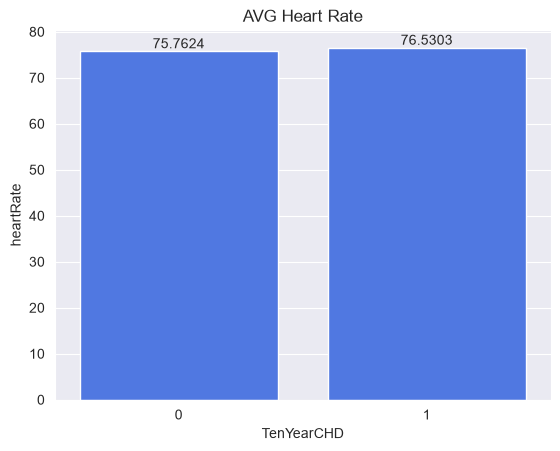

In [27]:
ax = sns.barplot(x="TenYearCHD", y="heartRate", data=df, ci=None)
plt.title("AVG Heart Rate")
for i in ax.containers:
    ax.bar_label(i)
plt.show()


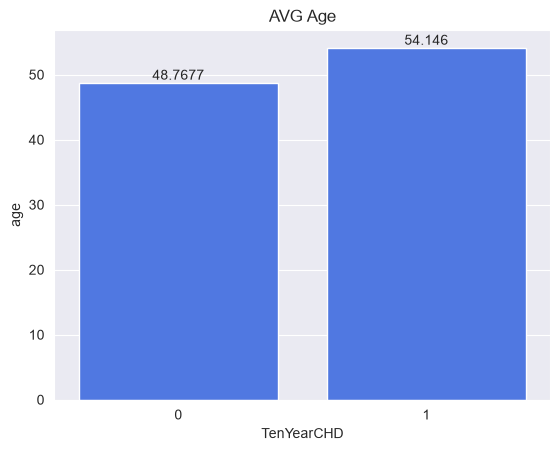

In [28]:
ax = sns.barplot(x="TenYearCHD", y="age", data=df, ci=None)
plt.title("AVG Age")
for i in ax.containers:
    ax.bar_label(i)
plt.show()


In [29]:
pd.crosstab(df["diabetes"], df["TenYearCHD"])


TenYearCHD,0,1
diabetes,,
0,3525,604
1,69,40


In [30]:
cro = pd.crosstab(df["diabetes"], df["TenYearCHD"])


In [31]:
from scipy.stats import chi2_contingency

chi2_contingency(cro)


Chi2ContingencyResult(statistic=np.float64(38.44172261466515), pvalue=np.float64(5.641334407100521e-10), dof=1, expected_freq=array([[3501.56347334,  627.43652666],
       [  92.43652666,   16.56347334]]))

In [32]:
g1 = df[df["TenYearCHD"] == 0]["heartRate"]
g2 = df[df["TenYearCHD"] == 1]["heartRate"]


In [33]:
from scipy.stats import ttest_ind

ttest_ind(g1, g2, nan_policy="omit")


TtestResult(statistic=np.float64(-1.4914728341322225), pvalue=np.float64(0.13591187840217403), df=np.float64(4235.0))

In [35]:
print(df.isna().sum())


male                 0
age                  0
currentSmoker        0
cigsPerDay           0
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64


In [37]:
import statsmodels.api as sm

df_clean = df.dropna()
print(df.shape, "->", df_clean.shape)

X = df_clean.drop(columns=["TenYearCHD"])
y = df_clean["TenYearCHD"]

X = sm.add_constant(X)

result = sm.Logit(y, X).fit()
print(result.summary())


(4238, 15) -> (3774, 15)
Optimization terminated successfully.
         Current function value: 0.376630
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:             TenYearCHD   No. Observations:                 3774
Model:                          Logit   Df Residuals:                     3759
Method:                           MLE   Df Model:                           14
Date:                Sat, 21 Nov 2026   Pseudo R-squ.:                  0.1166
Time:                        15:58:21   Log-Likelihood:                -1421.4
converged:                       True   LL-Null:                       -1608.9
Covariance Type:            nonrobust   LLR p-value:                 2.220e-71
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -8.6641      0.686    -12.639      0.000     -10.008  

<Axes: >

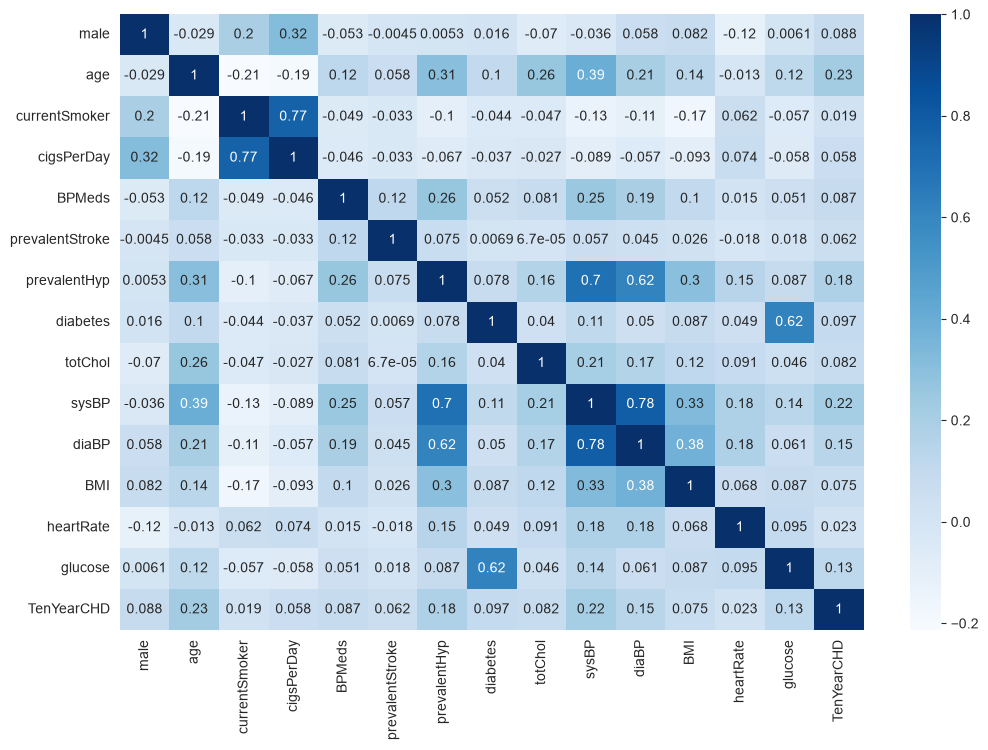

In [38]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap="Blues")


In [39]:
X = df.drop(columns=["TenYearCHD", "diabetes"])
y = df["TenYearCHD"]


## Preprocessing

Train Test Split

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)


Handling Null Values

In [41]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="mean")
X_train_filled = imputer.fit_transform(X_train)
X_test_filled = imputer.transform(X_test)


Feature Scaling (Standardization)

In [42]:
from sklearn.preprocessing import StandardScaler

stander = StandardScaler()
X_train = stander.fit_transform(X_train_filled)
X_test = stander.transform(X_test_filled)


## Logistic Regression Model

In [43]:
from sklearn.linear_model import LogisticRegression
logis = LogisticRegression(class_weight='balanced')
logis.fit(X_train,Y_train)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the fol

In [44]:
y_test_prid = logis.predict(X_test)


In [45]:
logis.predict_proba(X_test)


array([[0.11184045, 0.88815955],
       [0.65452258, 0.34547742],
       [0.83511989, 0.16488011],
       ...,
       [0.50814545, 0.49185455],
       [0.27183812, 0.72816188],
       [0.63556793, 0.36443207]], shape=(1060, 2))

Accuracy

In [46]:
from sklearn.metrics import accuracy_score

accuracy_score(Y_test, y_test_prid)


0.6679245283018868

Confusion Matrix

In [47]:
from sklearn.metrics import confusion_matrix
confusion_matrix(Y_test,y_test_prid)


array([[612, 287],
       [ 65,  96]])

Classification Report

In [48]:
from sklearn.metrics import classification_report
print(classification_report(Y_test,y_test_prid))


              precision    recall  f1-score   support

           0       0.90      0.68      0.78       899
           1       0.25      0.60      0.35       161

    accuracy                           0.67      1060
   macro avg       0.58      0.64      0.56      1060
weighted avg       0.80      0.67      0.71      1060



Tuning For Hyperparameters

In [49]:
param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "penalty": ["l1", "l2"],
    "class_weight": ["balanced"],
    "solver": ["liblinear", "lbfgs"],
}


In [50]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=logis, param_grid=param_grid, cv=5, scoring="recall", n_jobs=-1
)
grid_search.fit(X_train, Y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...ht='balanced')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...], 'class_weight': ['balanced'], 'penalty': ['l1', 'l2'], 'solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbo

In [51]:
grid_search.best_params_


{'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'}

In [52]:
from sklearn.linear_model import LogisticRegression
logis = LogisticRegression(C=1,class_weight='balanced',penalty='l1',solver='liblinear')
logis.fit(X_train,Y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.i

In [53]:
y_prid = logis.predict(X_test)


Model Evaluation

In [54]:
from sklearn.metrics import accuracy_score

accuracy_score(Y_test, y_prid)


0.6688679245283019

In [55]:
from sklearn.metrics import confusion_matrix

confusion_matrix(Y_test, y_prid)


array([[613, 286],
       [ 65,  96]])

In [56]:
from sklearn.metrics import classification_report

print(classification_report(Y_test, y_prid))


              precision    recall  f1-score   support

           0       0.90      0.68      0.78       899
           1       0.25      0.60      0.35       161

    accuracy                           0.67      1060
   macro avg       0.58      0.64      0.57      1060
weighted avg       0.80      0.67      0.71      1060



## Summary

1- Project Overview

This project analyzes the Framingham Heart Study dataset to identify key risk factors associated with the likelihood of developing heart disease within ten years. A Logistic Regression model was built to both interpret the impact of medical features and predict heart disease risk.

2- Data Understanding & Quality Assessment

The dataset was examined to understand its structure, data types, missing values, and overall quality. No duplicate records were found; however, several medical variables contained missing values, including cholesterol, glucose, heart rate, body mass index, and cigarettes per day.

3- Data Cleaning & Preprocessing

Appropriate methods were applied to handle missing data:

Continuous medical variables were imputed using their mean values.

Categorical variables were imputed using the most frequent value.

The number of cigarettes smoked per day was imputed using gender-based averages to preserve behavioral differences.

The education feature was removed due to its limited medical relevance.

After preprocessing, the dataset was complete and suitable for modeling.

4- Exploratory Data Analysis (EDA)

Exploratory analysis revealed clear differences between individuals who developed heart disease and those who did not:

Patients with heart disease tended to have:

Higher average age

Higher blood pressure levels

Higher cholesterol levels

Higher cigarette consumption

Higher heart rate

Gender-based comparisons also indicated differences in heart disease prevalence, highlighting the importance of demographic factors.

5- Statistical Analysis

Statistical tests were conducted to validate observed relationships:

Chi-square tests showed a strong univariate association between diabetes and heart disease.

T-tests indicated statistically significant differences in average heart rate between affected and unaffected individuals.

These tests supported the initial findings from the exploratory analysis.

6- Logistic Regression & Model Interpretation

A Logistic Regression model was used to assess the independent effect of each feature while controlling for other variables.

The results showed that:

Some variables that appeared significant in univariate analysis lost significance in the multivariate model.

This occurred due to multicollinearity, where multiple features represent overlapping medical information.

7- Feature Selection

Feature selection was guided by statistical significance, medical reasoning, and redundancy reduction:

Features that did not contribute independent information were removed.

For example, diabetes was excluded because it represents a general diagnosis, while glucose provides a more precise, continuous measurement of blood sugar levels.

This approach improved model interpretability and stability.

8- Model Training & Evaluation

The dataset was split into training and testing sets to ensure unbiased evaluation.

Model performance was assessed using:

Accuracy for overall performance

Confusion matrix to analyze prediction errors

Precision, Recall, and F1-score to evaluate class-level performance

Given the medical context, special emphasis was placed on Recall for heart disease cases to minimize missed diagnoses.

9- Conclusion

The analysis confirms that factors such as age, blood pressure, glucose level, cholesterol, and smoking behavior significantly influence heart disease risk. This project demonstrates the importance of distinguishing between simple statistical associations and independent predictors within multivariate models.

The final Logistic Regression model balances predictive performance with interpretability, making it suitable for both analytical insight and practical risk assessment.